In [43]:
# DEVELOPED BY : SUJIN M L
# REGISTER NUMBER : 212225040435
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler

In [44]:
df = pd.read_csv("C:\\Users\\acer\\Downloads\\Exp-1.csv")
df

,Input,Output
0,1,2
1,2,4
2,3,6
3,4,8
4,5,10
5,6,12
6,7,14
7,8,16
8,9,18
9,10,20


In [45]:
x = df[["Input"]].values
y = df[["Output"]].values

In [46]:
x_test, x_train, y_test, y_train = train_test_split(x,y,test_size=0.4,random_state=28)

In [47]:
scaler1 = MinMaxScaler()
scaler2 = MinMaxScaler()

x_train = scaler1.fit_transform(x_train)
x_test = scaler2.fit_transform(x_test)


In [48]:
x_train1 = torch.FloatTensor(x_train)
x_test1 = torch.FloatTensor(x_test)
y_train1 = torch.FloatTensor(y_train)
y_test1 = torch.FloatTensor(y_test)

In [49]:
class neuralnet(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(1,20),
            nn.ReLU(),
            nn.Linear(20,10),
            nn.ReLU(),
            nn.Linear(10,1)
        )
    def forward(self,x):
        return self.network(x)


In [50]:
model = neuralnet()
criterion =nn.MSELoss()
optimizer = optim.Adam(model.parameters(),lr=0.003)

In [51]:
epochs = 1000
loss_history = []

for i in range(epochs):
    optimizer.zero_grad()
    pred = model(x_train1)
    loss = criterion(pred,y_train1)
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if i%100==0:
        print(f"Epoch{i}:",loss.item())

    

Epoch0: 557.1666259765625
Epoch100: 346.9017333984375
Epoch200: 19.96269989013672
Epoch300: 14.360917091369629
Epoch400: 9.651622772216797
Epoch500: 6.0030598640441895
Epoch600: 3.3758466243743896
Epoch700: 1.68639075756073
Epoch800: 0.8405542969703674
Epoch900: 0.4218224585056305


In [52]:
with torch.no_grad():
    pred=model(x_test1)
    loss=criterion(pred,y_test1)
    print(loss.item())

41.05237579345703


In [53]:
model.eval()

input = torch.tensor(scaler1.transform([[22]]), dtype=torch.float32)

with torch.no_grad():
    pred = model(input)

print(pred.item())

43.23472213745117


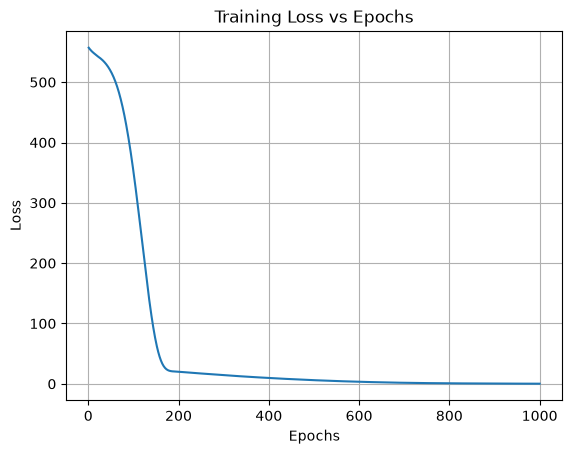

In [54]:
import matplotlib.pyplot as plt

plt.plot(range(1, epochs + 1), loss_history)
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Training Loss vs Epochs")
plt.grid(True)
plt.show()